# LAB1 – Bài 2 (Trang 28): Khảo sát và tiền xử lý dữ liệu Bank marketing
**Sinh viên:** Đinh Văn Bình – **MSSV:** 6351071007

## Câu 4: Vẽ biểu đồ khảo sát sự liên quan giữa Nghề nghiệp (job) và Trình độ học vấn (education) với khả năng đăng ký (y), phân biệt theo Tình trạng hôn nhân (marital)

*Ghi chú:* tương ứng với Câu 4 của phần hướng dẫn (Titanic: `embarked`, `pclass` – `survived`, phân biệt theo `sex`). Với Bank marketing:
- `embarked` (định danh) ↔ **job** (định danh),
- `pclass` (thứ tự) ↔ **education** (thứ tự),
- `sex` ↔ **marital** (giống Câu 3, vì dữ liệu không có giới tính).

In [1]:
print('Họ tên: Đinh Văn Bình - MSSV: 6351071007')

Họ tên: Đinh Văn Bình - MSSV: 6351071007


### Bước 1. Import thư viện và đọc dữ liệu

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
%matplotlib inline
from matplotlib import pyplot as plt

with open('bank-additional-full.csv') as f:
    df = pd.read_csv(f, sep=';')

df['subscribed'] = (df['y'] == 'yes').astype(int)
# Bỏ các dòng 'unknown' (giá trị thiếu) ở 3 thuộc tính đang khảo sát để biểu đồ rõ ràng
known = df[(df['marital'] != 'unknown') & (df['job'] != 'unknown') & (df['education'] != 'unknown')]
groups = ['married', 'single', 'divorced']
edu_order = ['illiterate', 'basic.4y', 'basic.6y', 'basic.9y', 'high.school',
             'professional.course', 'university.degree']
print('Số dòng dùng để vẽ:', len(known), '/', len(df))

Số dòng dùng để vẽ: 39191 / 41188


### Bước 2. Tỷ lệ đăng ký theo Nghề nghiệp (job), phân biệt theo tình trạng hôn nhân
Các nghề được sắp xếp theo tỷ lệ đăng ký chung giảm dần.

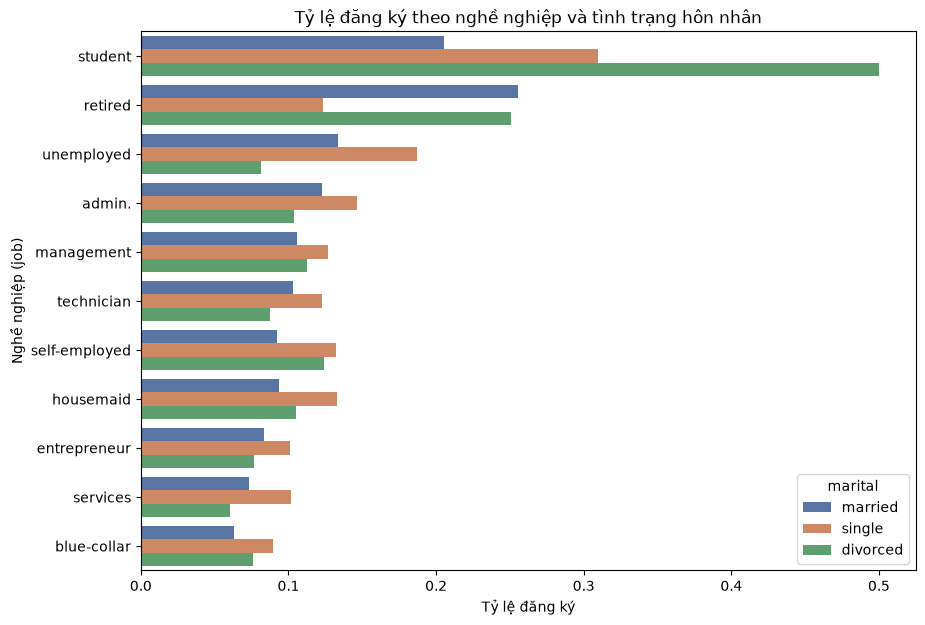

In [3]:
job_order = known.groupby('job')['subscribed'].mean().sort_values(ascending=False).index
plt.figure(figsize=(10, 7))
ax = sns.barplot(y='job', x='subscribed', hue='marital', data=known, order=job_order,
                 hue_order=groups, palette='deep', errorbar=None)
ax.set_xlabel('Tỷ lệ đăng ký')
ax.set_ylabel('Nghề nghiệp (job)')
_ = ax.set_title('Tỷ lệ đăng ký theo nghề nghiệp và tình trạng hôn nhân')

### Bước 3. Tỷ lệ đăng ký theo Trình độ học vấn (education), phân biệt theo tình trạng hôn nhân
Trục hoành sắp theo thứ tự trình độ (thuộc tính thứ tự – Ordinal), tương tự biểu đồ `pclass` của Titanic.

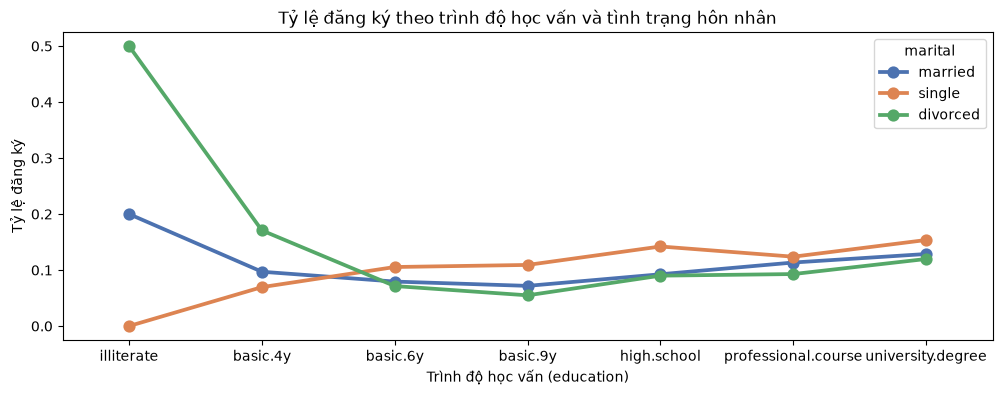

In [4]:
plt.figure(figsize=(12, 4))
ax = sns.pointplot(x='education', y='subscribed', hue='marital', data=known, order=edu_order,
                   hue_order=groups, palette='deep', errorbar=None)
ax.set_xlabel('Trình độ học vấn (education)')
ax.set_ylabel('Tỷ lệ đăng ký')
_ = ax.set_title('Tỷ lệ đăng ký theo trình độ học vấn và tình trạng hôn nhân')

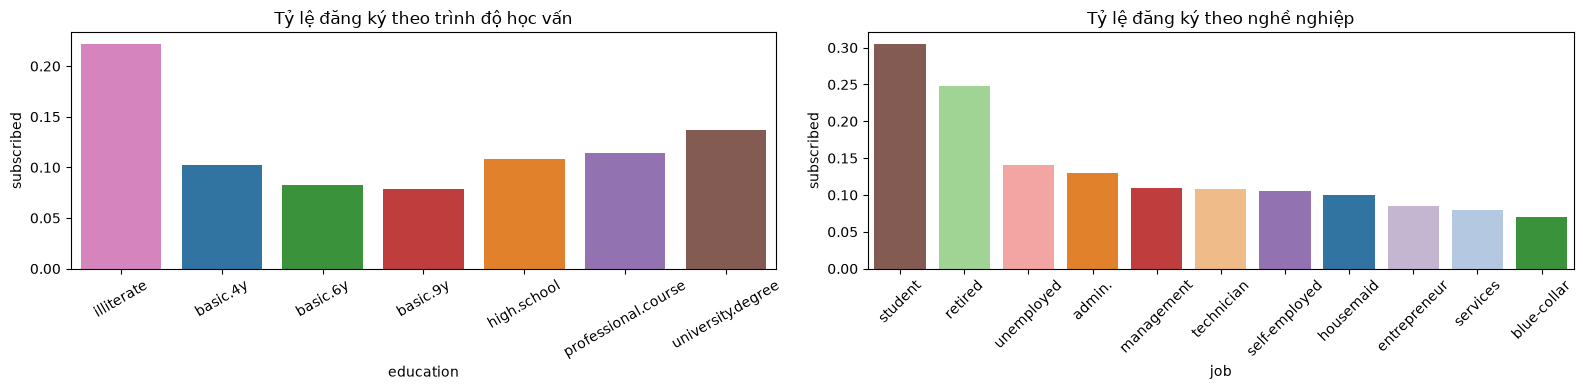

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
sns.barplot(x='education', y='subscribed', data=known, order=edu_order, hue='education',
            palette='tab10', legend=False, errorbar=None, ax=axes[0])
axes[0].set_title('Tỷ lệ đăng ký theo trình độ học vấn')
axes[0].tick_params(axis='x', rotation=30)
sns.barplot(x='job', y='subscribed', data=known, order=job_order, hue='job',
            palette='tab20', legend=False, errorbar=None, ax=axes[1])
axes[1].set_title('Tỷ lệ đăng ký theo nghề nghiệp')
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout()

### Bước 4. Bảng số liệu (minh họa cho nhận xét)

In [6]:
pd.set_option('display.width', 200)
for col, order in [('job', job_order), ('education', edu_order)]:
    t = (known.pivot_table(index=col, columns='marital', values='subscribed', aggfunc='mean') * 100).round(1)
    t = t.reindex(order)[groups]
    t['tất cả'] = (known.groupby(col)['subscribed'].mean() * 100).round(1)
    t['số khách'] = known.groupby(col).size()
    print(f'Tỷ lệ đăng ký (%) theo {col} và marital:')
    print(t, end='\n\n')

Tỷ lệ đăng ký (%) theo job và marital:
marital        married  single  divorced  tất cả  số khách
job                                                       
student           20.5    31.0      50.0    30.6       707
retired           25.6    12.4      25.1    24.7      1617
unemployed        13.4    18.7       8.1    14.0       990
admin.            12.3    14.6      10.4    12.9     10159
management        10.5    12.7      11.3    11.0      2798
technician        10.3    12.2       8.8    10.8      6520
self-employed      9.2    13.2      12.4    10.6      1387
housemaid          9.3    13.3      10.5    10.0      1015
entrepreneur       8.4    10.1       7.7     8.5      1396
services           7.3    10.2       6.0     8.0      3814
blue-collar        6.3     9.0       7.6     7.0      8788

Tỷ lệ đăng ký (%) theo education và marital:
marital              married  single  divorced  tất cả  số khách
education                                                       
illiterate        

### Nhận xét
**Nghề nghiệp (job):**
- Hai nhóm có tỷ lệ đăng ký cao vượt trội là **sinh viên (student) ~31%** và **người nghỉ hưu (retired) ~25%**. Kết quả này khớp với Câu 3: khách rất trẻ và khách trên 60 tuổi dễ đăng ký nhất.
- Thấp nhất là **công nhân (blue-collar) ~7%**, **dịch vụ (services) ~8%** và **chủ doanh nghiệp (entrepreneur) ~8.5%**. Hai nhóm admin., blue-collar đông khách nhất nhưng blue-collar lại đăng ký ít.
- **Phân biệt theo marital:** ở hầu hết các nghề, khách **độc thân** đăng ký nhiều hơn người đã kết hôn. Ngoại lệ là **retired**: người đã kết hôn và ly hôn đăng ký khoảng 25%, gấp đôi người độc thân (~12%). **Student** đã kết hôn có tỷ lệ thấp hơn hẳn student độc thân.

**Trình độ học vấn (education):**
- Nhìn chung, trình độ càng cao thì càng dễ đăng ký: **university.degree ~13.7%** cao nhất; nhóm **basic.6y, basic.9y** thấp nhất (~8%).
- **basic.4y (~10%)** cao hơn basic.6y/9y vì có nhiều khách lớn tuổi, đã nghỉ hưu. Nhóm ly hôn ở basic.4y đăng ký đến 17%.
- **illiterate** chỉ có 18 khách nên tỷ lệ (22%) không đáng tin cậy, các điểm dao động mạnh trên biểu đồ.
- **Phân biệt theo marital:** từ basic.6y trở lên, đường **single** luôn nằm trên married và divorced; riêng basic.4y thì ngược lại.

**Kết luận:** `job` ảnh hưởng mạnh đến khả năng đăng ký (student, retired cao; blue-collar, services thấp). `education` ảnh hưởng ở mức vừa phải. `marital` tạo ra khác biệt nhỏ hơn và chủ yếu gắn với độ tuổi.